# Who Gets Hospitalized with Flu?
### Analyzing 18 Seasons of CDC Influenza Hospitalization Data (2009–2026) by Age, Sex, Race and Virus Type

## Project Description
This project explores real influenza hospitalization data from the CDC's **Influenza Hospitalization Surveillance Network (FluSurv-NET)**. The network tracks lab-confirmed flu hospitalizations across selected counties in about 13 US states. The dataset covers **18 flu seasons (2009–10 to 2026–27)** and reports weekly and cumulative hospitalization rates per 100,000 people, broken down by **age group, sex, race/ethnicity, and virus type**.

**Workflow:**
1. **Data cleaning:** handle the raw CDC file format, missing values, and "Overall" summary rows.
2. **Exploratory data analysis:** compare hospitalization rates across age groups, sex, race/ethnicity, and virus types.
3. **Trend analysis:** compare seasons, find peak weeks, and spot unusually severe or mild years.
4. **Visualization:** use charts to show differences between groups and patterns over time.
5. **Insights and recommendations:** turn findings into practical suggestions for vaccination priorities and hospital preparation.

**Data source:** [CDC FluView Interactive – FluSurv-NET](https://gis.cdc.gov/GRASP/Fluview/FluHospRates.html)

> **Note:** The data is aggregated by group (not one row per patient) and covers selected areas, not the whole US.

---

## Objectives
1. **Identify high-risk groups:** find out which age groups, sexes and races/ethnicities have the highest flu hospitalization rates.
2. **Compare flu seasons:** measure how severe each season was (2009–10 to 2026–27) and find the worst and mildest seasons.
3. **Find seasonal patterns:** find when flu hospitalizations usually start rising, peak, and decline during the year.
4. **Compare virus types:** compare hospitalization rates caused by Influenza A vs. B, and by the A(H1N1) and A(H3N2) subtypes.
5. **Study the COVID-19 effect:** check how flu hospitalizations changed during the 2020–21 and 2021–22 seasons.
6. **Give recommendations:** turn the findings into practical suggestions for vaccination priorities and hospital planning.

---

## Dataset Features
**Size:** 28,758 rows × 16 columns

| Feature | Type | Description |
|---|---|---|
| `catchment` | Categorical | Area the data covers |
| `network` | Categorical | Surveillance network |
| `season` | Categorical | Flu season |
| `year` | Numeric (int) | Calendar year of the week |
| `week` | Numeric (int) | Week number of the year |
| `age_group` | Categorical | Age group |
| `sex` | Categorical | Sex |
| `race` | Categorical | Race/ethnicity |
| `virus_type` | Categorical | Flu virus type |
| `cumulative_rate` | Numeric (float) | Total hospitalizations per 100k so far in the season |
| `weekly_rate` | Numeric (float) | Hospitalizations per 100k in that week |
| `age_adjusted_cumulative_rate` | Numeric (float) | Cumulative rate adjusted for age |
| `age_adjusted_weekly_rate` | Numeric (float) | Weekly rate adjusted for age |
| `lower` | Numeric (float) | Lower nowcast estimate for recent weeks |
| `median` | Numeric (float) | Middle nowcast estimate for recent weeks |
| `upper` | Numeric (float) | Upper nowcast estimate for recent weeks |


In [ ]:
#download data from drive
import gdown
file_id = "1x60gn8dXp3ULtVdznpxYOAkLGhM2J2Wb"
destination = "data.csv"   # name you want to save as

gdown.download(f"https://drive.google.com/uc?id={file_id}", destination, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1x60gn8dXp3ULtVdznpxYOAkLGhM2J2Wb
To: /content/data.csv
100%|██████████| 3.25M/3.25M [00:00<00:00, 161MB/s]


'data.csv'

In [ ]:
#import libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


#Read Data
original_df = pd.read_csv('data.csv')
df = original_df.copy()
df.head()

,CATCHMENT,NETWORK,YEAR,YEAR.1,WEEK,AGE CATEGORY,SEX CATEGORY,RACE CATEGORY,VIRUS TYPE CATEGORY,CUMULATIVE RATE,WEEKLY RATE,AGE ADJUSTED CUMULATIVE RATE,AGE ADJUSTED WEEKLY RATE,LOWER,MEDIAN,UPPER
0,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,White,Overall,4.3,1.7,2.58,0.97,NaN,NaN,NaN
1,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Black,Overall,11.6,3.6,7.68,2.18,NaN,NaN,NaN
2,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Hispanic/Latino,Overall,12.8,4.8,7.50,2.73,NaN,NaN,NaN
3,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Asian/Pacific Islander,Overall,3.5,1.3,2.23,0.62,NaN,NaN,NaN
4,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,American Indian/Alaska Native,Overall,10.4,4.3,5.52,0.40,NaN,NaN,NaN


In [ ]:
df.head()

,CATCHMENT,NETWORK,YEAR,YEAR.1,WEEK,AGE CATEGORY,SEX CATEGORY,RACE CATEGORY,VIRUS TYPE CATEGORY,CUMULATIVE RATE,WEEKLY RATE,AGE ADJUSTED CUMULATIVE RATE,AGE ADJUSTED WEEKLY RATE,LOWER,MEDIAN,UPPER
0,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,White,Overall,4.3,1.7,2.58,0.97,NaN,NaN,NaN
1,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Black,Overall,11.6,3.6,7.68,2.18,NaN,NaN,NaN
2,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Hispanic/Latino,Overall,12.8,4.8,7.50,2.73,NaN,NaN,NaN
3,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Asian/Pacific Islander,Overall,3.5,1.3,2.23,0.62,NaN,NaN,NaN
4,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,American Indian/Alaska Native,Overall,10.4,4.3,5.52,0.40,NaN,NaN,NaN


In [ ]:
df.tail()

,CATCHMENT,NETWORK,YEAR,YEAR.1,WEEK,AGE CATEGORY,SEX CATEGORY,RACE CATEGORY,VIRUS TYPE CATEGORY,CUMULATIVE RATE,WEEKLY RATE,AGE ADJUSTED CUMULATIVE RATE,AGE ADJUSTED WEEKLY RATE,LOWER,MEDIAN,UPPER
28753,Entire Network,FluSurv-NET,2026-27,2027,35,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28754,Entire Network,FluSurv-NET,2026-27,2027,36,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28755,Entire Network,FluSurv-NET,2026-27,2027,37,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28756,Entire Network,FluSurv-NET,2026-27,2027,38,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28757,Entire Network,FluSurv-NET,2026-27,2027,39,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.shape

(28758, 16)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28758 entries, 0 to 28757
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   CATCHMENT                     28758 non-null  object 
 1   NETWORK                       28758 non-null  object 
 2   YEAR                          28758 non-null  object 
 3   YEAR.1                        28758 non-null  int64  
 4   WEEK                          28758 non-null  int64  
 5   AGE CATEGORY                  28758 non-null  object 
 6   SEX CATEGORY                  28758 non-null  object 
 7   RACE CATEGORY                 28758 non-null  object 
 8   VIRUS TYPE CATEGORY           28758 non-null  object 
 9   CUMULATIVE RATE               25773 non-null  float64
 10  WEEKLY RATE                   25680 non-null  float64
 11  AGE ADJUSTED CUMULATIVE RATE  12840 non-null  float64
 12  AGE ADJUSTED WEEKLY RATE      12840 non-null  float64
 13  L

In [ ]:
df.isnull().sum()

,0
CATCHMENT,0
NETWORK,0
YEAR,0
YEAR.1,0
WEEK,0
AGE CATEGORY,0
SEX CATEGORY,0
RACE CATEGORY,0
VIRUS TYPE CATEGORY,0
CUMULATIVE RATE,2985


note:1- columns ['LOWER', 'MEDIAN', 'UPPER'] are almost 100% nulls

2- ['WEEKLY_RATE'] has nulls in future unrecorded weeks

3- columns[AGE ADJUSTED CUMULATIVE RATE , AGE ADJUSTED WEEKLY RATE ]approximately half of the data is missing.

In [ ]:
df_clean=df.drop(columns=["MEDIAN","LOWER","UPPER"])
df_clean = df_clean.dropna(subset=['WEEKLY RATE'])
df_clean=df_clean.drop(columns=["AGE ADJUSTED CUMULATIVE RATE","AGE ADJUSTED WEEKLY RATE"])

In [ ]:
df_clean.isnull().sum()

,0
CATCHMENT,0
NETWORK,0
YEAR,0
YEAR.1,0
WEEK,0
AGE CATEGORY,0
SEX CATEGORY,0
RACE CATEGORY,0
VIRUS TYPE CATEGORY,0
CUMULATIVE RATE,0


In [ ]:
df_clean.columns

Index(['CATCHMENT', 'NETWORK', 'YEAR', 'YEAR.1', 'WEEK', 'AGE CATEGORY',
       'SEX CATEGORY', 'RACE CATEGORY', 'VIRUS TYPE CATEGORY',
       'CUMULATIVE RATE', 'WEEKLY RATE'],
      dtype='object')

In [ ]:
df["CATCHMENT"].unique()

array(['Entire Network'], dtype=object)

note: column(CATCHMENT) has only one value

*italicized text*

In [ ]:
df["NETWORK"].unique()

array(['FluSurv-NET'], dtype=object)

note: column(NETWORK) has only one value


In [ ]:
df_clean.drop(columns=["CATCHMENT","NETWORK"])

,YEAR,YEAR.1,WEEK,AGE CATEGORY,SEX CATEGORY,RACE CATEGORY,VIRUS TYPE CATEGORY,CUMULATIVE RATE,WEEKLY RATE
0,2009-10,2009,40,Overall,Overall,White,Overall,4.3,1.7
1,2009-10,2009,40,Overall,Overall,Black,Overall,11.6,3.6
2,2009-10,2009,40,Overall,Overall,Hispanic/Latino,Overall,12.8,4.8
3,2009-10,2009,40,Overall,Overall,Asian/Pacific Islander,Overall,3.5,1.3
4,2009-10,2009,40,Overall,Overall,American Indian/Alaska Native,Overall,10.4,4.3
...,...,...,...,...,...,...,...,...,...
28603,2026-27,2026,41,12-17 yr,Overall,Overall,Overall,0.3,0.1
28654,2026-27,2026,40,< 18,Overall,Overall,Overall,0.4,0.4
28655,2026-27,2026,41,< 18,Overall,Overall,Overall,0.8,0.4
28706,2026-27,2026,40,>= 18,Overall,Overall,Overall,1.2,1.2


In [ ]:
df_clean["YEAR"].unique()

array(['2009-10', '2010-11', '2011-12', '2012-13', '2013-14', '2014-15',
       '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2021-22',
       '2022-23', '2023-24', '2024-25', '2025-26', '2026-27'],
      dtype=object)

array(['2009-10', '2010-11', '2011-12', '2012-13', '2013-14', '2014-15',
       '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2021-22',
       '2022-23', '2023-24', '2024-25', '2025-26', '2026-27'],
      dtype=object)

In [ ]:
df_clean["YEAR"].value_counts()

,count
YEAR,
2023-24,2600
2025-26,2014
2021-22,1800
2014-15,1550
2017-18,1500
2013-14,1500
2010-11,1500
2012-13,1500
2011-12,1500


In [ ]:
df_clean["YEAR"]

,YEAR
0,2009-10
1,2009-10
2,2009-10
3,2009-10
4,2009-10
...,...
28603,2026-27
28654,2026-27
28655,2026-27
28706,2026-27


In [ ]:

df_clean[df_clean['YEAR'] == '2026-27'][['YEAR.1', 'WEEKLY RATE', 'WEEK']]

,YEAR.1,WEEKLY RATE,WEEK
26782,2026,1.5,40
26783,2026,1.1,40
26784,2026,0.5,40
26785,2026,0.9,40
26786,2026,1.1,40
...,...,...,...
28603,2026,0.1,41
28654,2026,0.4,40
28655,2026,0.4,41
28706,2026,1.2,40


note:Season `2026-27` only contains initial data for weeks 40 and 41


In [ ]:
df_clean = df_clean[df_clean['YEAR'] != '2026-27']

In [ ]:
df_clean["YEAR"].value_counts()

,count
YEAR,
2023-24,2600
2025-26,2014
2021-22,1800
2014-15,1550
2015-16,1500
2010-11,1500
2012-13,1500
2011-12,1500
2019-20,1500


In [ ]:
df_clean["YEAR.1"].unique()

array([2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019,
       2020, 2021, 2022, 2023, 2024, 2025, 2026])

,YEAR,YEAR.1
0,2009-10,2009
1,2009-10,2009
2,2009-10,2009
3,2009-10,2009
4,2009-10,2009
5,2009-10,2009
6,2009-10,2009
7,2009-10,2009
8,2009-10,2009
9,2009-10,2009


In [ ]:
df_clean[['YEAR', 'YEAR.1']].tail(20)

,YEAR,YEAR.1
26762,2025-26,2026
26763,2025-26,2026
26764,2025-26,2026
26765,2025-26,2026
26766,2025-26,2026
26767,2025-26,2026
26768,2025-26,2026
26769,2025-26,2026
26770,2025-26,2026
26771,2025-26,2026


In [ ]:
df_clean = df_clean.rename(columns={'YEAR': 'season', 'YEAR.1': 'calendar_year'})

In [ ]:
df_clean

,CATCHMENT,NETWORK,season,calendar_year,WEEK,AGE CATEGORY,SEX CATEGORY,RACE CATEGORY,VIRUS TYPE CATEGORY,CUMULATIVE RATE,WEEKLY RATE
0,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,White,Overall,4.3,1.7
1,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Black,Overall,11.6,3.6
2,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Hispanic/Latino,Overall,12.8,4.8
3,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Asian/Pacific Islander,Overall,3.5,1.3
4,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,American Indian/Alaska Native,Overall,10.4,4.3
...,...,...,...,...,...,...,...,...,...,...,...
26777,Entire Network,FluSurv-NET,2025-26,2026,35,>= 18,Overall,Overall,Overall,96.2,0.4
26778,Entire Network,FluSurv-NET,2025-26,2026,36,>= 18,Overall,Overall,Overall,96.7,0.4
26779,Entire Network,FluSurv-NET,2025-26,2026,37,>= 18,Overall,Overall,Overall,97.3,0.6
26780,Entire Network,FluSurv-NET,2025-26,2026,38,>= 18,Overall,Overall,Overall,98.3,1.0


In [ ]:
df_clean["WEEK"].unique()

array([40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52,  1,  2,  3,  4,
        5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 53, 18, 19, 20,
       21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37,
       38, 39])

In [ ]:
df_clean[['season', 'calendar_year',"WEEK"]].head(20)

,season,calendar_year,WEEK
0,2009-10,2009,40
1,2009-10,2009,40
2,2009-10,2009,40
3,2009-10,2009,40
4,2009-10,2009,40
5,2009-10,2009,40
6,2009-10,2009,40
7,2009-10,2009,40
8,2009-10,2009,40
9,2009-10,2009,40


In [ ]:
df_clean[['season', 'calendar_year',"WEEK"]].tail(20)

,season,calendar_year,WEEK
26762,2025-26,2026,20
26763,2025-26,2026,21
26764,2025-26,2026,22
26765,2025-26,2026,23
26766,2025-26,2026,24
26767,2025-26,2026,25
26768,2025-26,2026,26
26769,2025-26,2026,27
26770,2025-26,2026,28
26771,2025-26,2026,29


In [ ]:
df_clean["AGE CATEGORY"].unique()

array(['Overall', '0-4 yr', '5-17 yr', '18-49 yr', '50-64 yr', '>= 65 yr',
       '65-74 yr', '75-84 yr', '>= 85', '18-29 yr', '30-39 yr',
       '40-49 yr', '0-< 1 yr', '1-4 yr', '>= 75', '5-11  yr', '12-17 yr',
       '< 18', '>= 18'], dtype=object)

In [ ]:
pd.crosstab(df_clean['season'], df_clean['AGE CATEGORY'])

AGE CATEGORY,0-4 yr,0-< 1 yr,1-4 yr,12-17 yr,18-29 yr,18-49 yr,30-39 yr,40-49 yr,5-11 yr,5-17 yr,50-64 yr,65-74 yr,75-84 yr,< 18,>= 18,>= 65 yr,>= 75,>= 85,Overall
season,,,,,,,,,,,,,,,,,,,
2009-10,90,30,30,30,30,90,30,30,30,90,90,30,30,30,30,90,30,30,300
2010-11,150,30,30,30,30,150,30,30,30,150,150,30,30,30,30,150,30,30,360
2011-12,150,30,30,30,30,150,30,30,30,150,150,30,30,30,30,150,30,30,360
2012-13,150,30,30,30,30,150,30,30,30,150,150,30,30,30,30,150,30,30,360
2013-14,150,30,30,30,30,150,30,30,30,150,150,30,30,30,30,150,30,30,360
2014-15,155,31,31,31,31,155,31,31,31,155,155,31,31,31,31,155,31,31,372
2015-16,150,30,30,30,30,150,30,30,30,150,150,30,30,30,30,150,30,30,360
2016-17,150,30,30,30,30,150,30,30,30,150,150,30,30,30,30,150,30,30,360
2017-18,150,30,30,30,30,150,30,30,30,150,150,30,30,30,30,150,30,30,360


note:The data is repeated across similar age segments.


In [ ]:
df_clean["SEX CATEGORY"].unique()

array(['Overall', 'Male', 'Female'], dtype=object)

,AGE CATEGORY,SEX CATEGORY
0,Overall,Overall
1,Overall,Overall
2,Overall,Overall
3,Overall,Overall
4,Overall,Overall
...,...,...
26777,>= 18,Overall
26778,>= 18,Overall
26779,>= 18,Overall
26780,>= 18,Overall


In [ ]:
df_clean.columns

Index(['CATCHMENT', 'NETWORK', 'season', 'calendar_year', 'WEEK',
       'AGE CATEGORY', 'SEX CATEGORY', 'RACE CATEGORY', 'VIRUS TYPE CATEGORY',
       'CUMULATIVE RATE', 'WEEKLY RATE'],
      dtype='object')

In [ ]:
df_clean['RACE CATEGORY'].unique()

array(['White', 'Black', 'Hispanic/Latino', 'Asian/Pacific Islander',
       'American Indian/Alaska Native', 'Overall'], dtype=object)

In [ ]:
df_clean['VIRUS TYPE CATEGORY'].unique()

array(['Overall', 'Influenza A', 'Influenza B', 'A(H1N1)pdm09', 'A(H3N2)'],
      dtype=object)

In [ ]:
df_clean['CUMULATIVE RATE'].unique()

array([ 4.3, 11.6, 12.8, ..., 94.8, 98.3, 99.4])

In [ ]:
df_clean['CUMULATIVE RATE']

,CUMULATIVE RATE
0,4.3
1,11.6
2,12.8
3,3.5
4,10.4
...,...
26777,96.2
26778,96.7
26779,97.3
26780,98.3


In [ ]:
df_clean['WEEKLY RATE'].unique()

array([ 1.7,  3.6,  4.8, ..., 28.1, 61.6, 71.2])

In [ ]:
df_clean[['WEEKLY RATE', 'CUMULATIVE RATE']].describe()

,WEEKLY RATE,CUMULATIVE RATE
count,25604.000000,25604.000000
mean,1.838978,33.053178
std,5.347399,74.027363
min,0.000000,0.000000
25%,0.100000,0.700000
50%,0.370539,7.900000
75%,1.500000,33.200000
max,139.200000,1117.000000


In [ ]:
df_clean.sort_values('WEEKLY RATE', ascending=False)[['season', 'WEEK', 'AGE CATEGORY', 'WEEKLY RATE', 'CUMULATIVE RATE']].head()

,season,WEEK,AGE CATEGORY,WEEKLY RATE,CUMULATIVE RATE
8361,2014-15,52,>= 85,139.2,303.8
8362,2014-15,53,>= 85,137.0,440.8
12873,2017-18,1,>= 85,133.5,368.4
26212,2025-26,53,>= 85,114.4,343.3
12872,2017-18,52,>= 85,110.8,234.9


The increase is due to the elderly population and peak winter weeks.

In [ ]:
df_clean.dtypes

,0
CATCHMENT,object
NETWORK,object
season,object
calendar_year,int64
WEEK,int64
AGE CATEGORY,object
SEX CATEGORY,object
RACE CATEGORY,object
VIRUS TYPE CATEGORY,object
CUMULATIVE RATE,float64


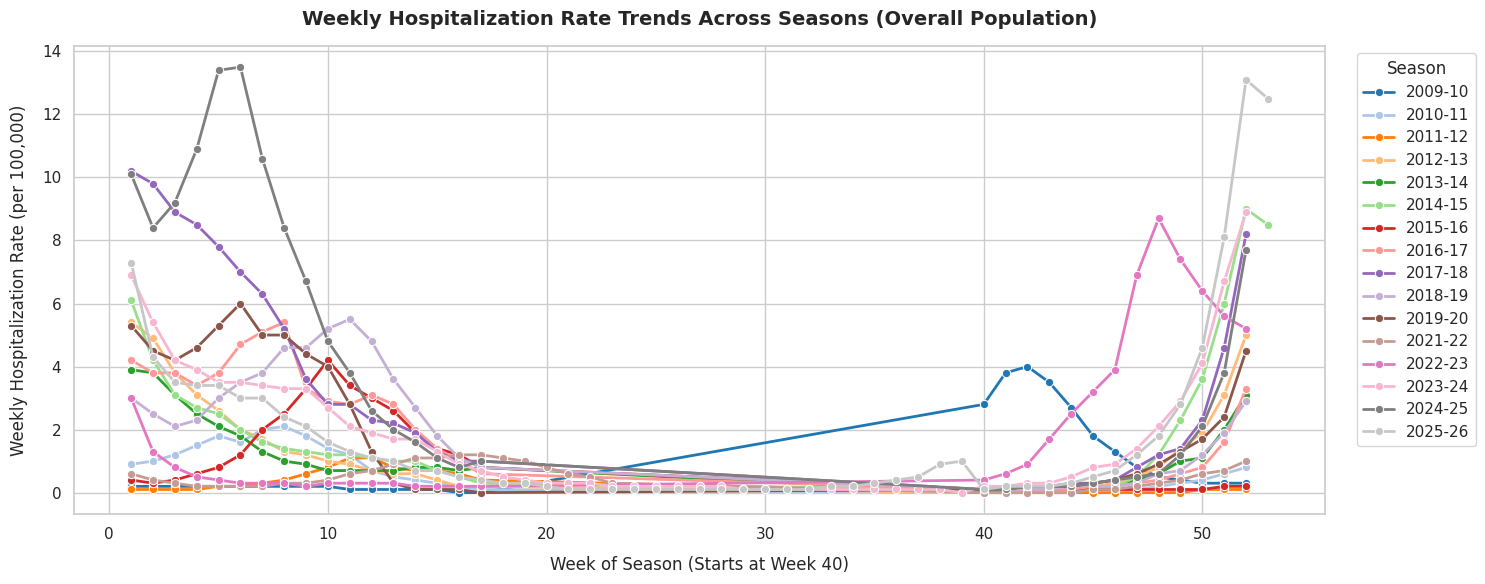

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_overall = df_clean[
    (df_clean['AGE CATEGORY'] == 'Overall') &
    (df_clean['SEX CATEGORY'] == 'Overall') &
    (df_clean['RACE CATEGORY'] == 'Overall') &
    (df_clean['VIRUS TYPE CATEGORY'] == 'Overall')
].copy()

plt.figure(figsize=(15, 6))
sns.set_theme(style='whitegrid')

sns.lineplot(
    data=df_overall,
    x='WEEK',
    y='WEEKLY RATE',
    hue='season',
    palette='tab20',
    linewidth=2,
    marker='o'
)

plt.title('Weekly Hospitalization Rate Trends Across Seasons (Overall Population)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Week of Season (Starts at Week 40)', fontsize=12, labelpad=10)
plt.ylabel('Weekly Hospitalization Rate (per 100,000)', fontsize=12, labelpad=10)
plt.legend(title='Season', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

Standard Peak Window: High hospitalization activity consistently occurs during winter between Weeks 50 and 6 (December through February).   
Severest Seasons: Season 2025-26 reached the highest early peak (Week 52), while 2024-25 recorded the highest late-season peak (Weeks 5–6).
Early Anomaly Waves: Season 2022-23 spiked unusually early at Week 48 (post-COVID immunity gap), similar to the 2009–10 H1N1 pandemic surge.  

/tmp/ipykernel_2344/270800122.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


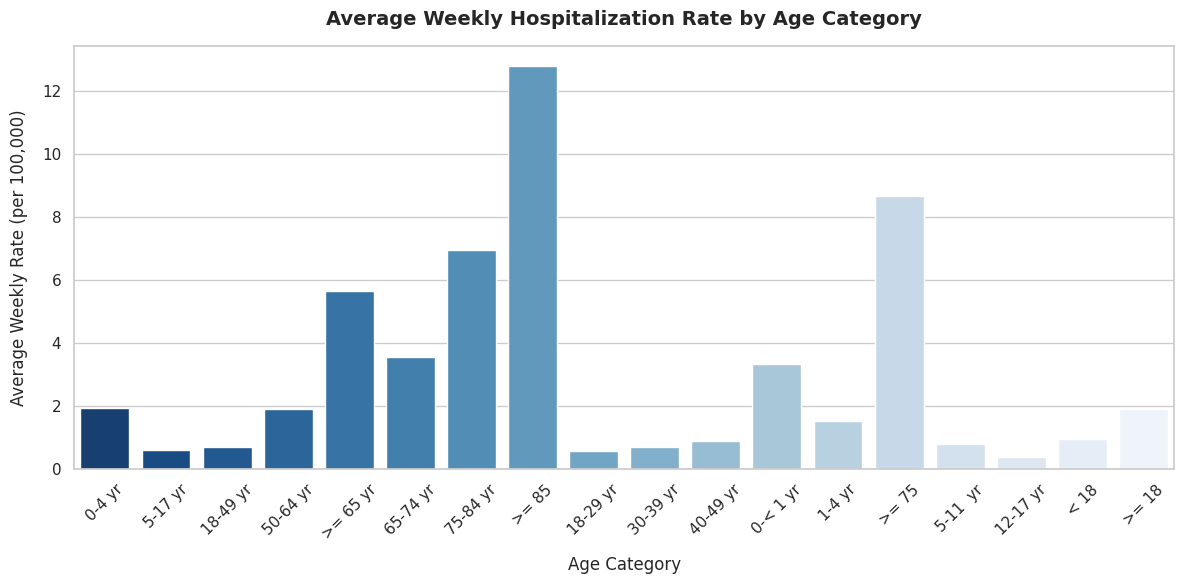

In [ ]:
df_age = df_clean[
    (df_clean['AGE CATEGORY'] != 'Overall') &
    (df_clean['RACE CATEGORY'] == 'Overall') &
    (df_clean['VIRUS TYPE CATEGORY'] == 'Overall')
].copy()

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_age,
    x='AGE CATEGORY',
    y='WEEKLY RATE',
    estimator='mean',
    errorbar=None,
    palette='Blues_r'
)

plt.title('Average Weekly Hospitalization Rate by Age Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Age Category', fontsize=12, labelpad=10)
plt.ylabel('Average Weekly Rate (per 100,000)', fontsize=12, labelpad=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2344/4023440070.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Race Category', bbox_to_anchor=(1.02, 1), loc='upper left')


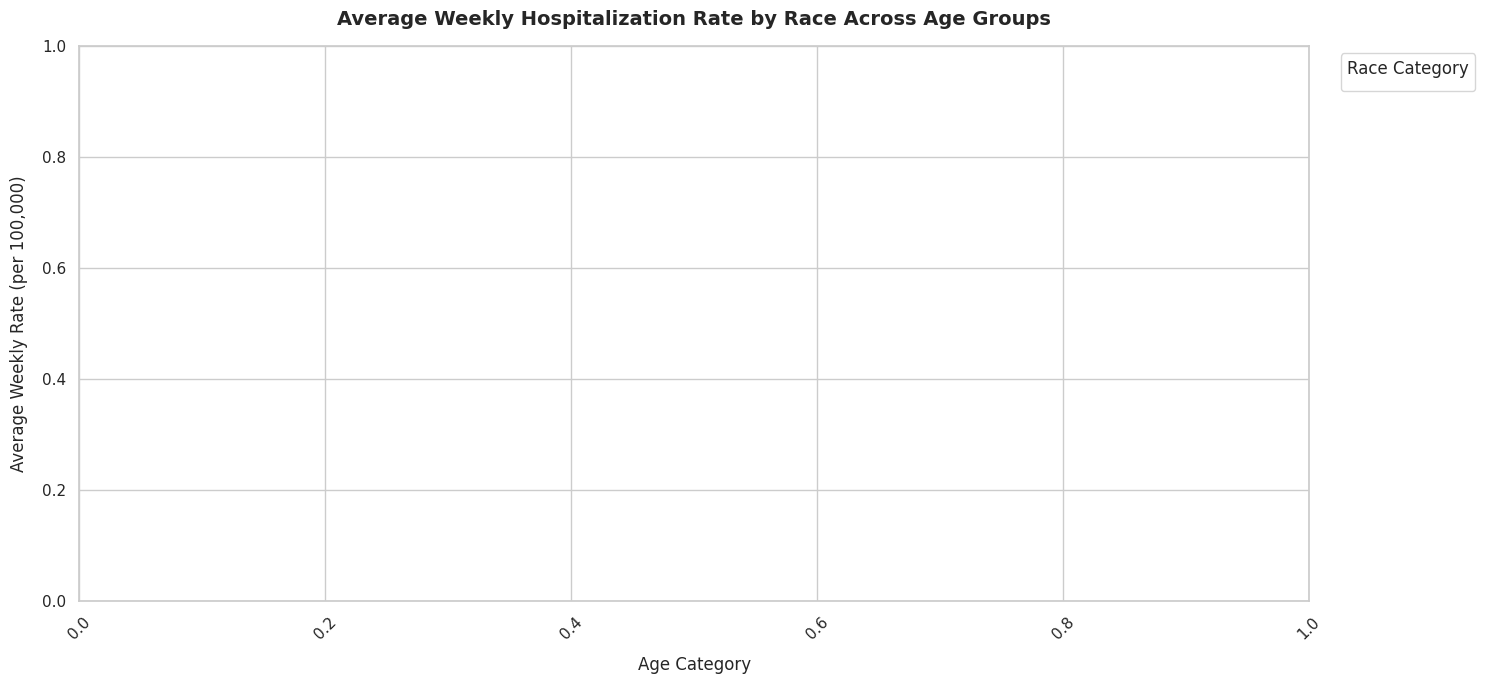

In [ ]:
standard_ages = [
    '0-< 1 yr', '1-4 yr', '5-17 yr',
    '18-49 yr', '50-64 yr', '65-74 yr',
    '75-84 yr', '>= 85'
]

df_race = df_clean[
    (df_clean['AGE CATEGORY'].isin(standard_ages)) &
    (df_clean['RACE CATEGORY'] != 'Overall') &
    (df_clean['SEX CATEGORY'] == 'Overall') &
    (df_clean['VIRUS TYPE CATEGORY'] == 'Overall')
].copy()

plt.figure(figsize=(15, 7))
sns.barplot(
    data=df_race,
    x='AGE CATEGORY',
    y='WEEKLY RATE',
    hue='RACE CATEGORY',
    estimator='mean',
    errorbar=None,
    palette='Set2'
)

plt.title('Average Weekly Hospitalization Rate by Race Across Age Groups', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Age Category', fontsize=12, labelpad=10)
plt.ylabel('Average Weekly Rate (per 100,000)', fontsize=12, labelpad=10)
plt.legend(title='Race Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2344/3746344242.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


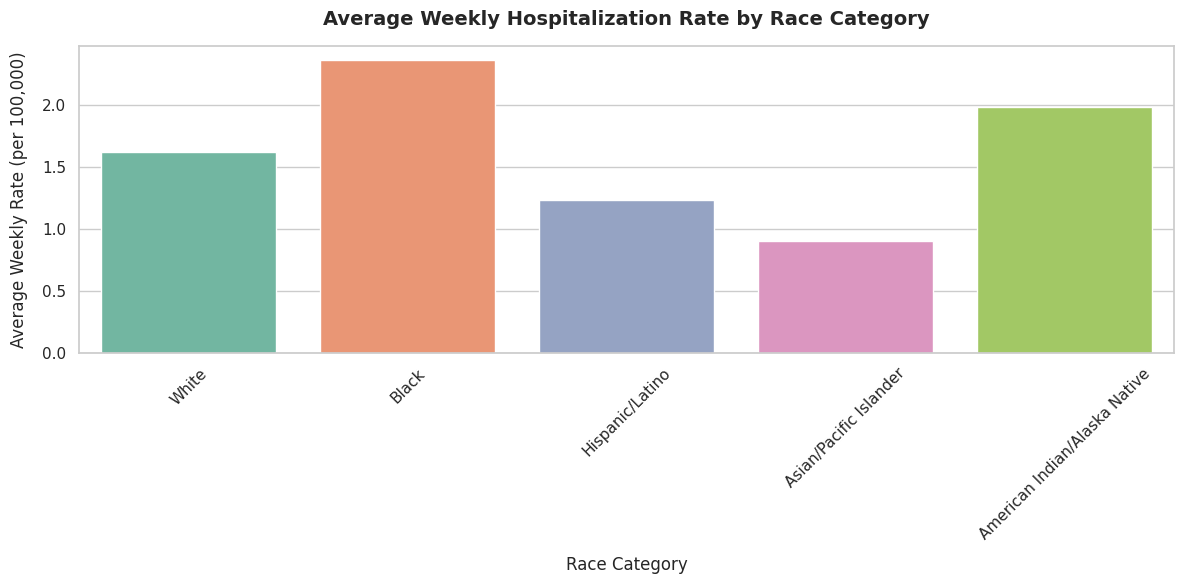

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_race_clean = df_clean[
    (df_clean['RACE CATEGORY'] != 'Overall') &
    (df_clean['AGE CATEGORY'] == 'Overall') &
    (df_clean['SEX CATEGORY'] == 'Overall') &
    (df_clean['VIRUS TYPE CATEGORY'] == 'Overall')
].copy()

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_race_clean,
    x='RACE CATEGORY',
    y='WEEKLY RATE',
    estimator='mean',
    errorbar=None,
    palette='Set2'
)

plt.title('Average Weekly Hospitalization Rate by Race Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Race Category', fontsize=12, labelpad=10)
plt.ylabel('Average Weekly Rate (per 100,000)', fontsize=12, labelpad=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Highest Risk: Black populations record the highest rate , followed by American Indian / Alaska Native .Moderate Risk: White populations sit in the middle .Lowest Risk: Hispanic / Latino and Asian / Pacific Islander.

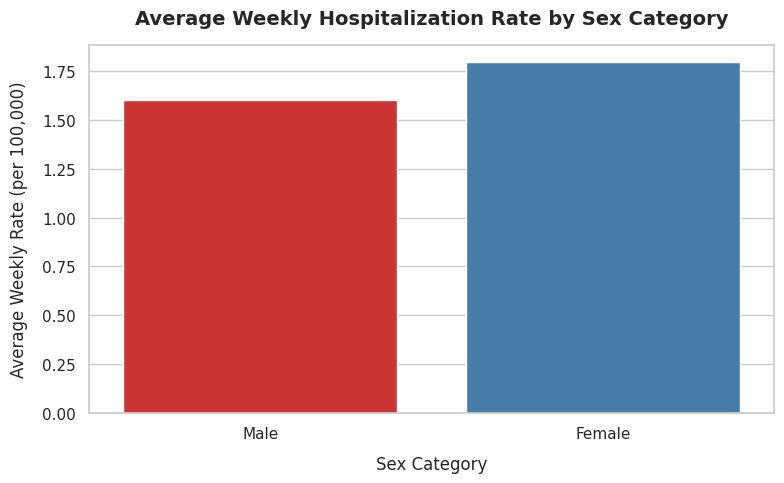

In [ ]:

df_sex = df_clean[
    (df_clean['SEX CATEGORY'].isin(['Male', 'Female'])) &
    (df_clean['AGE CATEGORY'] == 'Overall') &
    (df_clean['RACE CATEGORY'] == 'Overall') &
    (df_clean['VIRUS TYPE CATEGORY'] == 'Overall')
].copy()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_sex,
    x='SEX CATEGORY',
    y='WEEKLY RATE',
    hue='SEX CATEGORY',
    estimator='mean',
    errorbar=None,
    palette='Set1',
    legend=False
)

plt.title('Average Weekly Hospitalization Rate by Sex Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Sex Category', fontsize=12, labelpad=10)
plt.ylabel('Average Weekly Rate (per 100,000)', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

Higher Female Rate: Females show a slightly higher average hospitalization rate compares to male

In [ ]:
df_clean.columns

Index(['CATCHMENT', 'NETWORK', 'season', 'calendar_year', 'WEEK',
       'AGE CATEGORY', 'SEX CATEGORY', 'RACE CATEGORY', 'VIRUS TYPE CATEGORY',
       'CUMULATIVE RATE', 'WEEKLY RATE'],
      dtype='object')

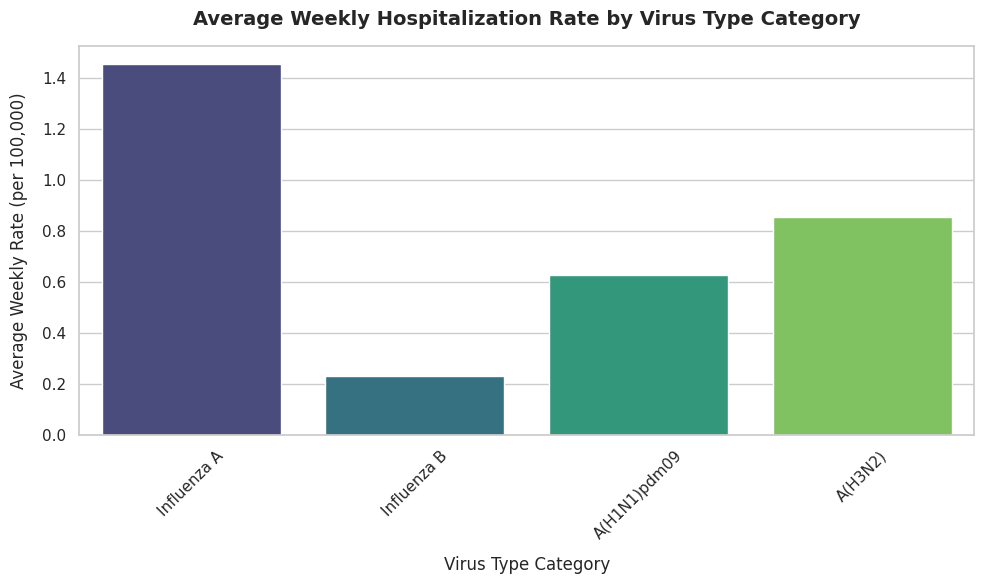

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_virus = df_clean[
    (df_clean['VIRUS TYPE CATEGORY'] != 'Overall') &
    (df_clean['AGE CATEGORY'] == 'Overall') &
    (df_clean['RACE CATEGORY'] == 'Overall') &
    (df_clean['SEX CATEGORY'] == 'Overall')
].copy()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_virus,
    x='VIRUS TYPE CATEGORY',
    y='WEEKLY RATE',
    hue='VIRUS TYPE CATEGORY',
    estimator='mean',
    errorbar=None,
    palette='viridis',
    legend=False
)

plt.title('Average Weekly Hospitalization Rate by Virus Type Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Virus Type Category', fontsize=12, labelpad=10)
plt.ylabel('Average Weekly Rate (per 100,000)', fontsize=12, labelpad=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Influenza A is by far the primary driver of hospitalizations , whereas Influenza B accounts for a minor fraction .

Leading Subtype: Among Influenza A subtypes, A(H3N2) exhibits the highest hospitalization burden , followed by A(H1N1).